# Lab Assignment 1 - Convolutional Neural Networks

This notebook contains the **Part B** assignment tasks.
Use the lab session notebook for Part A demos and architecture notes (A9) if needed. Implement your solutions in the code cells below.

# Part B Assignment

Use this section to develop the main tasks and, optionally, the two challenges. Each task has a broad description followed by one consolidated answer code cell. You may design different interfaces, experiments and plots. Justify your choices and follow the accompanying assignment description for submission requirements.

## Task 1. Study and Prepare the Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from pathlib import Path
# cpu as a fallback
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [2]:
from IPython.display import display
from torchvision.datasets.utils import download_and_extract_archive
DATA_ROOT = Path("data")
try:
  database = datasets.CIFAR10(DATA_ROOT, train=True, download=False)
except:
  # faster than download with datasets
  download_and_extract_archive(
      "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz",
      download_root=str(DATA_ROOT),
      filename="cifar-10-python.tar.gz",
      md5="c58f30108f718f92721af3b95e74349a",
  )
  database = datasets.CIFAR10(DATA_ROOT, train=True, download=False)

labels = np.asarray(database.targets)
class_names = database.classes

print("Images:", database.data.shape, database.data.dtype)
print("Pixel range:", database.data.min(), database.data.max())
display(
    pd.DataFrame(
        {
            "class": class_names,
            "count": np.bincount(labels, minlength=10),
        }
    )
)

Images: (50000, 32, 32, 3) uint8
Pixel range: 0 255


,class,count
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


**Q: What does an example represent, and how are the classes distributed?**

An example is a 32×32 RGB image with a single class label from the ten CIFAR-10 categories. The official training set has 50,000 images with pixel values in [0, 255], and the classes are balanced (5,000 images per class).

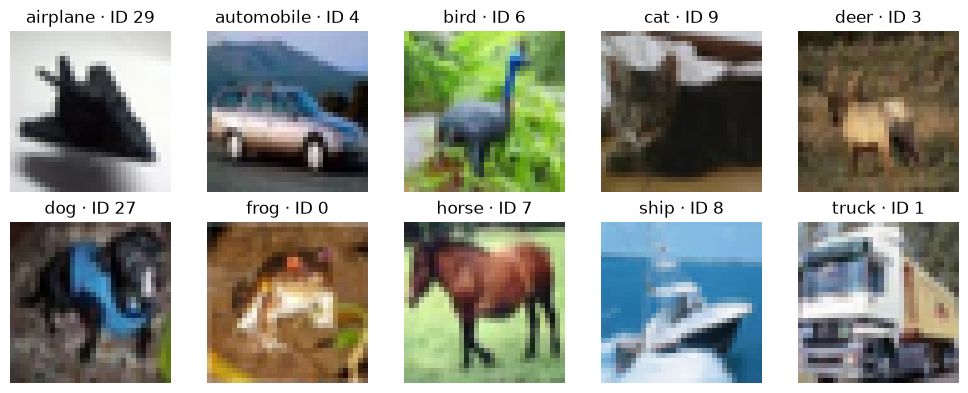

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for target, ax in enumerate(axes.flat):
    image_id = int(np.flatnonzero(labels == target)[0])
    ax.imshow(database.data[image_id])
    ax.set_title(f"{class_names[target]} · ID {image_id}")
    ax.axis("off")
fig.tight_layout()
plt.show()

In [4]:

from sklearn.model_selection import train_test_split
SEED = 2223

train_ids, val_ids = train_test_split(
    np.arange(len(database)),
    test_size=0.1,
    stratify=labels,
    random_state=SEED,
)
train_ids, val_ids = np.sort(train_ids), np.sort(val_ids)
assert set(train_ids).isdisjoint(val_ids)

print("Training / validation:", len(train_ids), len(val_ids))


Training / validation: 45000 5000


In [5]:
test_database = datasets.CIFAR10(DATA_ROOT, train=False, download=False)
test_ids = np.arange(len(test_database))
print("Test:", len(test_ids))
assert set(train_ids).isdisjoint(val_ids)

Test: 10000


In [6]:
from tqdm import tqdm

channel_sum = np.zeros(3)
channel_square_sum = np.zeros(3)
pixel_count = 0

# we process images in a batch of 256
for start in tqdm(range(0, len(train_ids), 256)):
    pixels = database.data[train_ids[start : start + 256]].astype(np.float64) / 255
    channel_sum += pixels.sum(axis=(0, 1, 2)) # sum across samples in a batch, image heights, image widths
    channel_square_sum += np.square(pixels).sum(axis=(0, 1, 2))
    pixel_count += np.prod(pixels.shape[:3])

mean = channel_sum / pixel_count
std = np.sqrt(np.maximum(channel_square_sum / pixel_count - mean**2, 1e-12))
stats = {"mean": mean.tolist(), "std": std.tolist()}
display(pd.DataFrame(stats, index=["red", "green", "blue"]))

  0%|          | 0/176 [00:00<?, ?it/s]

 10%|█         | 18/176 [00:00<00:00, 174.07it/s]

 20%|██        | 36/176 [00:00<00:00, 176.36it/s]

 31%|███       | 54/176 [00:00<00:00, 174.72it/s]

 41%|████      | 72/176 [00:00<00:00, 175.67it/s]

 52%|█████▏    | 91/176 [00:00<00:00, 178.24it/s]

... (2 outputs left out)

 82%|████████▏ | 145/176 [00:00<00:00, 177.39it/s]

 93%|█████████▎| 163/176 [00:00<00:00, 178.12it/s]

100%|██████████| 176/176 [00:00<00:00, 177.76it/s]

,mean,std
red,0.491318,0.247001
green,0.482180,0.243401
blue,0.446389,0.261544


In [7]:
class RawImages(Dataset):
    def __init__(self, dataset, ids):
        self.dataset = dataset
        self.ids = list(map(int, ids))

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):  # ty: ignore[lost-keyword-for-regular-parameter]
        image_id = self.ids[idx]
        image, target = self.dataset[image_id]
        return TF.to_tensor(image), int(target), image_id

In [8]:
def prepare_inputs(raw, stats):
    mean = raw.new_tensor(stats["mean"])[None, :, None, None]
    std = raw.new_tensor(stats["std"])[None, :, None, None]
    return (raw - mean) / std

**Q: Which preprocessing steps are needed for the two architectures?**

Both AlexNet and ResNet use the CIFAR-10 adaptations from Part A9, so they take native 3×32×32 inputs. We apply the same preprocessing to both: convert uint8 images to float tensors in [0, 1], then normalize each channel with the mean and standard deviation computed on the training split only.

**Q: How is the dataset preprocessed and splitted?**

We split the official training set into 45,000 training and 5,000 validation images (stratified 90/10, seed 2223). The official 10,000-image test set is held out for final evaluation. Images are converted to [0, 1] tensors and normalized with training-set mean/std.

In [9]:
BATCH_SIZE = 128

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    RawImages(database, train_ids),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=g
)
val_loader = DataLoader(
    RawImages(database, val_ids),
    batch_size=BATCH_SIZE,
    shuffle=False,
    generator=g
)
test_loader = DataLoader(
    RawImages(test_database, test_ids),
    batch_size=BATCH_SIZE,
    shuffle=False,
    generator=g
)

print(f"Training loader: {len(train_loader)} batches")
print(f"Validation loader: {len(val_loader)} batches")
print(f"Test loader: {len(test_loader)} batches")

Training loader: 352 batches
Validation loader: 40 batches
Test loader: 79 batches


**Q: How to control the randomness in the experiment?**

We fix the train and validation split and the `DataLoader` shuffling with a fixed `SEED = 2223`.

This keeps the data partition and batch order reproducible across runs.


## Task 2. Implement and Compare the Models
Implement and train AlexNet and ResNet using PyTorch layers, starting from the architectures and CIFAR-10 adaptations discussed in A9. Explain any differences from the original designs, observe feature shapes and compare the models under a justified compute budget. Do not use pretrained weights or readily-available model constructors.

Choose your optimizer, training schedule, checkpoint rule and evaluation metrics. Justify your choices. Report numerical performance, parameter counts, training cost, number of trained samples and relevant limitations. You are free to define different model construction, training and evaluation rather than following part A.

### Task 2 implementation and experiment protocol

Run Task 1 first, then run the following cells in order. Select the repository's
`.venv/Scripts/python.exe` as the local notebook kernel.

**Architectures.** AlexNet uses all five A9 convolutions and three linear layers;
its 3x3, stride-1 convolutions and 2x2 pooling preserve information in 32x32 images.
The classifier is 4096 -> 1024 -> 512 -> 10 with dropout 0.5. This is the suggested
CIFAR-10 adaptation, not the original ImageNet model (large initial kernel/stride,
larger classifier and local response normalization). ResNet uses the A9 ResNet-18
layout: a 3x3 stride-1 stem without initial max pooling, four stages of two basic
blocks, global average pooling and a 512 -> 10 head. Convolutions followed by
BatchNorm have `bias=False` because BatchNorm already supplies a learnable shift.
Both models are built from PyTorch layers, without pretrained weights.

A 3x3 convolution combines nearby pixels/features; padding 1 preserves spatial
size at stride 1, while stride 2 downsamples. Later stages combine features over
larger receptive fields. ResNet adds `F(x)` to an identity shortcut or a learned
1x1 projection when shape changes; this provides a direct gradient path through
the block. Both heads output raw logits: CrossEntropyLoss applies the appropriate
log-softmax internally.

**Controlled comparison.** Both models use the same split, raw-to-normalized input
preparation, batch size, seed, fresh shuffle generator and number of epochs.
SGD with momentum 0.9 and initial learning rate 0.01 provides one shared baseline;
cosine decay reduces the learning rate once per completed epoch. There is no
augmentation or weight decay here; AlexNet retains A9's dropout. Architecture and
its prescribed dropout/BatchNorm differ, so this is not an isolated test of depth.
The best checkpoint is the epoch with highest validation accuracy, breaking ties
by lower validation cross-entropy. Test data never select a checkpoint.

The full budget is **20 epochs per model**, with batch size **64** for the local
4 GB GPU. Equal epochs mean equal sample exposure, not equal time or FLOPs.
`RUN_MODE = "full"` runs the actual experiment. For a quick pipeline check,
set it to `"smoke"` (one epoch on 512 training / 256 validation images).
Rerun the configuration and later cells after changing modes. Smoke accuracy
is not a report result.
If memory is insufficient, lower batch size for **both** models before comparison.
Fixed seeds and deterministic cuDNN settings reduce randomness; exact agreement
across devices, software versions or all GPU operations is not guaranteed.

In [10]:
# AlexNet
class AlexNet(nn.Module):
    def __init__(self, dropout=0.5):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(
                in_channels=64,
                out_channels=192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(
                in_channels=192,
                out_channels=384,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=384,
                out_channels=256,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            # Conv5 from A9: preserve 256 x 8 x 8 before the last pooling.
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(
                in_features=4096,
                out_features=1024
            ),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(
                in_features=1024,
                out_features=512
            ),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(
                in_features=512,
                out_features=10
            )
        )

    def forward(self, x):
        return self.network(x)

AlexNet()(torch.randn(2, 3, 32, 32)).shape

torch.Size([2, 10])

In [11]:
# BasicBlock

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                stride=stride,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=out_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                stride=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
        )

        self.shortcut = self.build_shortcut(in_channels, out_channels, stride)
        self.relu = nn.ReLU()

    def build_shortcut(self, in_channels, out_channels, stride):
        if stride == 1 and in_channels == out_channels:
            return nn.Identity()
        else:
            return nn.Sequential(
                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        return self.relu(self.shortcut(x) + self.network(x))


print(BasicBlock(64, 64, 1)(torch.randn(2, 64, 32, 32)).shape)
print(BasicBlock(64, 128, 2)(torch.randn(2, 64, 32, 32)).shape)

torch.Size([2, 64, 32, 32])
torch.Size([2, 128, 16, 16])


In [12]:
# ResNet

class ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # Stage 1
            BasicBlock(64, 64, 1),
            BasicBlock(64, 64, 1),

            # Stage 2
            BasicBlock(64, 128, 2),
            BasicBlock(128, 128, 1),

            # Stage 3
            BasicBlock(128, 256, 2),
            BasicBlock(256, 256, 1),

            # Stage 4
            BasicBlock(256, 512, 2),
            BasicBlock(512, 512, 1),
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.Linear(
                in_features=512,
                out_features=10
            )
        )

    def forward(self, x):
        return self.network(x)

ResNet()(torch.randn(2, 3, 32, 32)).shape

torch.Size([2, 10])

In [13]:
import json
import platform
import random
import sys
import time
import uuid
from datetime import datetime, timezone
import torchvision

MODEL_BUILDERS = {"AlexNet": AlexNet, "ResNet18": ResNet}

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()

def inspect_model(model):
    # Inspect on CPU in eval mode so dummy inputs do not update BatchNorm.
    rows, handles = [], []
    was_training = model.training
    def record(name):
        def hook(module, inputs, output):
            rows.append({
                "layer": name, "type": type(module).__name__,
                "output_shape": tuple(output.shape),
                "parameters": sum(p.numel() for p in module.parameters(recurse=False)),
            })
        return hook
    try:
        for name, module in model.named_modules():
            if not list(module.children()):
                handles.append(module.register_forward_hook(record(name)))
        model.eval()
        with torch.no_grad():
            output = model(torch.zeros(2, 3, 32, 32))
        assert output.shape == (2, 10)
    finally:
        for handle in handles:
            handle.remove()
        model.train(was_training)
    return pd.DataFrame(rows)

architecture_rows = []
shape_tables = {}
for name, builder in MODEL_BUILDERS.items():
    set_seed(SEED)
    model = builder()
    shape_tables[name] = inspect_model(model)
    architecture_rows.append({
        "model": name,
        "parameters": sum(p.numel() for p in model.parameters()),
        "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
    })
    print(name)
    display(shape_tables[name])
    del model
architecture_summary = pd.DataFrame(architecture_rows)
display(architecture_summary)

AlexNet


,layer,type,output_shape,parameters
0,network.0,Conv2d,"(2, 64, 32, 32)",1792
1,network.1,ReLU,"(2, 64, 32, 32)",0
2,network.2,MaxPool2d,"(2, 64, 16, 16)",0
3,network.3,Conv2d,"(2, 192, 16, 16)",110784
4,network.4,ReLU,"(2, 192, 16, 16)",0
5,network.5,MaxPool2d,"(2, 192, 8, 8)",0
6,network.6,Conv2d,"(2, 384, 8, 8)",663936
7,network.7,ReLU,"(2, 384, 8, 8)",0
8,network.8,Conv2d,"(2, 256, 8, 8)",884992
9,network.9,ReLU,"(2, 256, 8, 8)",0


ResNet18


,layer,type,output_shape,parameters
0,network.0,Conv2d,"(2, 64, 32, 32)",1728
1,network.1,BatchNorm2d,"(2, 64, 32, 32)",128
2,network.2,ReLU,"(2, 64, 32, 32)",0
3,network.3.shortcut,Identity,"(2, 64, 32, 32)",0
4,network.3.network.0,Conv2d,"(2, 64, 32, 32)",36864
...,...,...,...,...
60,network.10.network.4,BatchNorm2d,"(2, 512, 4, 4)",1024
61,network.10.relu,ReLU,"(2, 512, 4, 4)",0
62,network.11,AdaptiveAvgPool2d,"(2, 512, 1, 1)",0
63,network.12,Flatten,"(2, 512)",0


,model,parameters,trainable_parameters
0,AlexNet,6976842,6976842
1,ResNet18,11173962,11173962


In [14]:
RUN_MODE = "full"  # Full baseline: 20 epochs on the complete training split.
assert RUN_MODE in {"smoke", "full"}
config = {
    "mode": RUN_MODE, "seed": SEED,
    "epochs": 1 if RUN_MODE == "smoke" else 20,
    "batch_size": 64, "learning_rate": 0.01,
    "momentum": 0.9, "weight_decay": 0.0,
    "augmentation": False, "precision": "float32",
}

def stratified_subset(ids, size):
    ids = np.asarray(ids)
    if len(ids) <= size:
        return ids.copy()
    selected, _ = train_test_split(
        ids, train_size=size, stratify=labels[ids], random_state=config["seed"]
    )
    return np.sort(selected)

task2_train_ids = stratified_subset(train_ids, 512) if RUN_MODE == "smoke" else train_ids.copy()
task2_val_ids = stratified_subset(val_ids, 256) if RUN_MODE == "smoke" else val_ids.copy()
assert set(task2_train_ids).isdisjoint(task2_val_ids)

# Each run gets a new directory, so earlier checkpoints are not overwritten.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
output_dir = Path("outputs") / "task2" / f"{RUN_MODE}_{run_id}"
output_dir.mkdir(parents=True, exist_ok=False)
environment = {
    "python": sys.version, "platform": platform.platform(),
    "torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
    "numpy": np.__version__, "device": str(device),
    "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
    "cuda_runtime": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "cudnn_deterministic": torch.backends.cudnn.deterministic,
}
(output_dir / "config.json").write_text(json.dumps({
    "config": config, "environment": environment, "normalization": stats,
    "train_size": len(task2_train_ids), "validation_size": len(task2_val_ids),
    "normalization_fit_size": len(train_ids),
}, indent=2), encoding="utf-8")
np.savez(output_dir / "split_ids.npz", train_ids=task2_train_ids, val_ids=task2_val_ids)
architecture_summary.to_csv(output_dir / "architectures.csv", index=False)
for name, table in shape_tables.items():
    table.to_csv(output_dir / f"{name}_shapes.csv", index=False)
print(config)
print("Device:", device, "| Output directory:", output_dir.resolve())
print("Training samples per model:", config["epochs"] * len(task2_train_ids))

{'mode': 'full', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'learning_rate': 0.01, 'momentum': 0.9, 'weight_decay': 0.0, 'augmentation': False, 'precision': 'float32'}
Device: cuda | Output directory: E:\ID2223\lab\ID2223-Scalable-Machine-Learning-and-Deep-Learning\assignments\ass1\outputs\task2\full_20261117T213705Z_b52818aa
Training samples per model: 900000


In [15]:
def make_task2_loaders():
    # Recreate this generator for EACH model, giving both the same epoch orders.
    options = {"batch_size": config["batch_size"], "num_workers": 0,
               "pin_memory": device.type == "cuda"}
    train_dataset = RawImages(database, task2_train_ids)
    validation_dataset = RawImages(database, task2_val_ids)
    return {
        "train": DataLoader(train_dataset, shuffle=True,
                            generator=torch.Generator().manual_seed(config["seed"]), **options),
        "train_eval": DataLoader(train_dataset, shuffle=False, **options),
        "val": DataLoader(validation_dataset, shuffle=False, **options),
    }

def train_one_epoch(model, loader, optimizer, normalization_stats):
    model.train()  # Enable dropout and update BatchNorm statistics.
    loss_sum, correct, count = 0.0, 0, 0
    for raw, targets, image_ids in loader:
        raw = raw.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(prepare_inputs(raw, normalization_stats))
        loss = nn.functional.cross_entropy(logits, targets)
        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite training loss; check input statistics and learning rate.")
        loss.backward()
        optimizer.step()
        batch_size = targets.size(0)
        loss_sum += loss.item() * batch_size
        correct += (logits.argmax(1) == targets).sum().item()
        count += batch_size
    return {"loss": loss_sum / count, "accuracy": correct / count, "samples": count}

@torch.inference_mode()
def evaluate(model, loader, normalization_stats):
    model.eval()  # Disable dropout; use stored BatchNorm statistics.
    loss_sum, correct, count = 0.0, 0, 0
    for raw, targets, image_ids in loader:
        raw = raw.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        logits = model(prepare_inputs(raw, normalization_stats))
        loss_sum += nn.functional.cross_entropy(logits, targets, reduction="sum").item()
        correct += (logits.argmax(1) == targets).sum().item()
        count += targets.size(0)
    return {"loss": loss_sum / count, "accuracy": correct / count, "samples": count}

def train_model(name):
    set_seed(config["seed"])
    loaders = make_task2_loaders()
    model = MODEL_BUILDERS[name]().to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=config["learning_rate"],
                                momentum=config["momentum"], weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["epochs"])
    checkpoint_path = output_dir / f"{name}_best.pt"
    history = []
    best_key, best_epoch = (-float("inf"), -float("inf")), None
    samples_seen = 0
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    synchronize_device()
    run_start = time.perf_counter()
    for epoch in range(1, config["epochs"] + 1):
        learning_rate = optimizer.param_groups[0]["lr"]
        synchronize_device()
        start = time.perf_counter()
        online = train_one_epoch(model, loaders["train"], optimizer, stats)
        synchronize_device()
        train_seconds = time.perf_counter() - start
        start = time.perf_counter()
        # Evaluate both splits with frozen weights and dropout disabled.
        train_metrics = evaluate(model, loaders["train_eval"], stats)
        val_metrics = evaluate(model, loaders["val"], stats)
        synchronize_device()
        eval_seconds = time.perf_counter() - start
        samples_seen += online["samples"]
        row = {
            "epoch": epoch, "learning_rate": learning_rate,
            "online_train_loss": online["loss"],
            "train_loss": train_metrics["loss"], "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"], "val_accuracy": val_metrics["accuracy"],
            "train_seconds": train_seconds, "eval_seconds": eval_seconds,
            "samples_seen": samples_seen,
        }
        history.append(row)
        # A larger tuple wins: accuracy first, then smaller loss; exact ties keep the earlier epoch.
        key = (val_metrics["accuracy"], -val_metrics["loss"])
        if key > best_key:
            best_key, best_epoch = key, epoch
            torch.save({
                "model_name": name, "epoch": epoch, "config": dict(config),
                "stats": stats, "class_names": class_names,
                "val_loss": val_metrics["loss"], "val_accuracy": val_metrics["accuracy"],
                "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            }, checkpoint_path)
        scheduler.step()
        pd.DataFrame(history).to_csv(output_dir / f"{name}_history.csv", index=False)
        print(f"{name} {epoch:02d}/{config['epochs']} | "
              f"train {train_metrics['accuracy']:.1%}, val {val_metrics['accuracy']:.1%} | "
              f"val loss {val_metrics['loss']:.4f} | train {train_seconds:.1f}s", flush=True)
    synchronize_device()
    wall_seconds = time.perf_counter() - run_start
    peak_memory = torch.cuda.max_memory_allocated(device) / 2**20 if device.type == "cuda" else None
    summary = {
        "model": name, "mode": config["mode"], "epochs": config["epochs"],
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch, "best_val_accuracy": best_key[0], "best_val_loss": -best_key[1],
        "trained_samples": samples_seen,
        "training_seconds": sum(row["train_seconds"] for row in history),
        "evaluation_seconds": sum(row["eval_seconds"] for row in history),
        "wall_seconds": wall_seconds, "peak_cuda_allocated_mib": peak_memory,
        "checkpoint": str(checkpoint_path),
    }
    # Each model runs separately, keeping GPU memory usage bounded.
    del model, optimizer, scheduler
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return pd.DataFrame(history), summary

In [16]:
histories, summaries = {}, []
for name in MODEL_BUILDERS:
    histories[name], summary = train_model(name)
    summaries.append(summary)
    comparison = pd.DataFrame(summaries)
    comparison.to_csv(output_dir / "comparison.csv", index=False)
display(comparison)
if RUN_MODE == "smoke":
    print("SMOKE CHECK ONLY: set RUN_MODE='full' and rerun from the configuration cell for report results.")

AlexNet 01/20 | train 41.3%, val 42.3% | val loss 1.5562 | train 19.8s


AlexNet 02/20 | train 54.0%, val 53.2% | val loss 1.2837 | train 19.4s


AlexNet 03/20 | train 64.4%, val 62.0% | val loss 1.0348 | train 19.3s


AlexNet 04/20 | train 73.7%, val 71.1% | val loss 0.8068 | train 19.0s


AlexNet 05/20 | train 78.3%, val 74.7% | val loss 0.7344 | train 19.1s


AlexNet 06/20 | train 81.6%, val 76.4% | val loss 0.6906 | train 19.2s


... (31 outputs left out)

ResNet18 18/20 | train 100.0%, val 85.0% | val loss 0.7234 | train 49.7s


ResNet18 19/20 | train 100.0%, val 85.1% | val loss 0.7203 | train 49.8s


ResNet18 20/20 | train 100.0%, val 84.9% | val loss 0.7308 | train 49.7s


,model,mode,epochs,parameters,best_epoch,best_val_accuracy,best_val_loss,trained_samples,training_seconds,evaluation_seconds,wall_seconds,peak_cuda_allocated_mib,checkpoint
0,AlexNet,full,20,6976842,20,0.8410,0.886199,900000,383.811340,205.711761,590.169943,178.731445,outputs\task2\full_20261117T213705Z_b52818aa\A...
1,ResNet18,full,20,11173962,19,0.8508,0.720289,900000,981.659177,409.584306,1392.115603,426.244141,outputs\task2\full_20261117T213705Z_b52818aa\R...


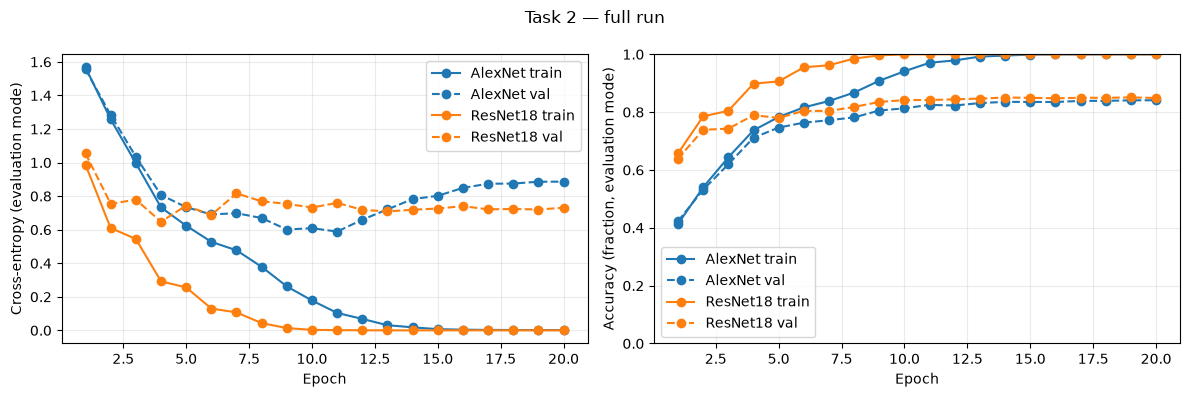

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    line, = axes[0].plot(history["epoch"], history["train_loss"], marker="o", label=f"{name} train")
    color = line.get_color()
    axes[0].plot(history["epoch"], history["val_loss"], "--o", color=color, label=f"{name} val")
    axes[1].plot(history["epoch"], history["train_accuracy"], "-o", color=color, label=f"{name} train")
    axes[1].plot(history["epoch"], history["val_accuracy"], "--o", color=color, label=f"{name} val")
axes[0].set_ylabel("Cross-entropy (evaluation mode)")
axes[1].set_ylabel("Accuracy (fraction, evaluation mode)")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.25)
fig.suptitle(f"Task 2 — {RUN_MODE} run")
fig.tight_layout()
fig.savefig(output_dir / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Task 2 discussion and conclusions

We trained both models for 20 epochs on the same 45,000 training images and used
5,000 validation images to select checkpoints. Each model processed 900,000
training examples in total, counting repeated visits across epochs. We used batch
size 64 and seed 2223 on an NVIDIA GeForce RTX 3050 Ti Laptop GPU. Both models used
SGD with momentum and the same cosine learning-rate schedule. This run used no
data augmentation or weight decay; AlexNet kept its dropout probability of 0.5.

The table reports the checkpoint with the highest validation accuracy for each
model. The loss shown is from that checkpoint. All accuracy values are validation
results; the test set has not been evaluated.

| Measurement | AlexNet | ResNet-18 |
|---|---:|---:|
| Parameters | 6,976,842 | 11,173,962 |
| Selected epoch | 20 | 19 |
| Validation accuracy | 84.10% | 85.08% |
| Validation loss at selected epoch | 0.8862 | 0.7203 |
| Training accuracy at selected epoch | 99.98% | 100.00% |
| Training time, excluding evaluation | 6.40 min | 16.36 min |
| Evaluation time | 3.43 min | 6.83 min |
| Total run time, including evaluation and saving | 9.84 min | 23.20 min |
| Peak allocated CUDA tensor memory | 178.73 MiB | 426.24 MiB |

Both models learned the training data well. ResNet reached 100% training accuracy
at epoch 12, while AlexNet reached 99.98% by epoch 20. The training and validation
curves both use evaluation mode, so dropout is disabled and BatchNorm uses its
stored statistics. At the selected checkpoints, the accuracy gaps were 15.88
percentage points for AlexNet and 14.92 for ResNet. These gaps, together with the
near-zero training losses, show overfitting. The curves give little evidence that
either model lacked the capacity to fit this training set.

AlexNet's validation loss fell to its minimum of 0.5888
at epoch 11, then rose to 0.8862 by epoch 20.
Its validation accuracy still improved from 82.52% to
84.10% over that period. Accuracy counts correct class
choices; cross-entropy also depends on the probability assigned to the true class.
The model can therefore classify more images correctly while its loss increases.
One possible explanation is that it becomes more confident in some of its remaining
mistakes. We have not measured calibration, so the curves alone do not establish
how well its confidence scores match actual correctness.

ResNet also showed a gap between its best loss and best accuracy. Its lowest
validation loss was 0.6474 at epoch 4, when
accuracy was 78.94%. Its highest accuracy was
85.08% at epoch 19. Since our checkpoint
rule prioritizes accuracy, the saved models are AlexNet at epoch 20 and ResNet at
epoch 19. Choosing by validation loss would select different epochs. We kept the
rule fixed throughout this comparison, and reloading both saved checkpoints
reproduced their recorded validation scores.

ResNet learned faster when progress was measured in epochs. At epoch 10, its
validation accuracy was 84.16%, compared with 81.32% for AlexNet. Residual
connections give gradients a direct path through the network, which can help
optimization. This experiment does not isolate their effect: the models also
differ in width, depth and BatchNorm, and AlexNet uses dropout. A comparison with
the same network trained with and without skip connections would be needed to
measure the effect of the residual connections themselves.

ResNet's final advantage was 0.98 percentage points in validation accuracy.
It had 1.60 times as many parameters and took 2.36 times as
long for the complete run. Equal epochs gave the models the same number of
training examples, but their compute costs differed. The timing includes data
loading and transfers; evaluation time covers a full pass over both the training
and validation splits after every epoch. The memory figures measure tensors
allocated by PyTorch, so they exclude other applications and reserved allocator
memory. These measurements do not establish inference speed.

For further experiments on this laptop, we would choose AlexNet when training
time is limited: it reached 84.10% validation accuracy in 9.84 minutes. ResNet is
an option when the extra 0.98 percentage points justify a 23.20-minute run.
This choice is based on one seed, one data split and the shared training settings.
We have not tuned each model separately or measured variation across repeated
runs. Different training budgets or hardware could change the comparison, and
the validation set was also used to select checkpoints. Final test results are
still needed after the experimental choices are fixed.

The next step in Task 3 is to test whether regularization reduces the observed
training-validation gaps. We can compare L2 settings and dropout probabilities
while keeping the data split and training budget fixed. Repeating the baselines
with additional seeds would help show whether the small accuracy difference
between the models is consistent.

These results come from run `full_20261117T213705Z_b52818aa`, using `comparison.csv`,
`AlexNet_history.csv` and `ResNet18_history.csv`. A copy of the [saved results](results/task2/full_20261117T213705Z_b52818aa/README.md) is included in this repository.


### Reading the results and final testing

The displayed training and validation curves both use `eval()` after each epoch,
so dropout and changing weights do not confound the train/validation gap.
`online_train_loss` separately records the loss used during optimization.
Losses are sample-weighted, including the final smaller batch; accuracy is a
fraction in [0, 1]. Training time includes input loading, transfers and updates;
evaluation time includes an additional full training-set and validation-set pass.
Wall time additionally includes checkpoint/CSV writing. GPU operations are
synchronized at timing boundaries. Peak allocated CUDA memory is PyTorch tensor
memory for the run, not total GPU memory or reserved allocator memory.

Use `comparison.csv`, the shape tables and `learning_curves.png` in the report.
Discuss the accuracy/cost tradeoff, training duration and single-seed limitation;
do not infer that a model is inherently worse from a short or unconverged run.
Checkpoints store model weights and preprocessing metadata for evaluation, not
optimizer state for exact training resumption. Configuration, environment and
split IDs are saved beside them. Generated artifacts live under `outputs/task2/`.

Leave final testing disabled while choosing models, regularization or augmentation
in later tasks. Once all choices are frozen, enable the next cell to evaluate the
best **full-run** checkpoints on the held-out official test set. Do not tune on
these scores. For a previous run, load its comparison CSV into `comparison` and
set `output_dir` to that run's folder before using the cell.

In [18]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    final_rows = []
    for row in comparison.to_dict("records"):
        checkpoint = torch.load(row["checkpoint"], map_location="cpu", weights_only=True)
        if checkpoint["config"]["mode"] != "full":
            raise ValueError("Final test evaluation requires full-run checkpoints, not smoke checkpoints.")
        model = MODEL_BUILDERS[checkpoint["model_name"]]().to(device)
        model.load_state_dict(checkpoint["state_dict"])
        final_loader = DataLoader(
            RawImages(test_database, test_ids),
            batch_size=checkpoint["config"]["batch_size"], shuffle=False, num_workers=0,
            pin_memory=device.type == "cuda",
        )
        metrics = evaluate(model, final_loader, checkpoint["stats"])
        final_rows.append({"model": checkpoint["model_name"], "best_epoch": checkpoint["epoch"],
                           "test_loss": metrics["loss"], "test_accuracy": metrics["accuracy"],
                           "test_samples": metrics["samples"]})
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()
    final_results = pd.DataFrame(final_rows)
    final_results.to_csv(output_dir / "final_test.csv", index=False)
    display(final_results)
else:
    print("Test set remains held out. Enable only after all experimental choices are frozen.")

Test set remains held out. Enable only after all experimental choices are frozen.


## Task 3. Investigate Capacity and Regularization
Investigate how model capacity (n_channels/width, depth, etc.) and regularization influence learning and generalization. Select a feasible set of comparisons and justify what you change and hold fixed. Include L2 regularization, a condition without dropout and two dropout probabilities of your choice. Use learning curves and deterministic training/validation evaluation to distinguish underfitting, overfitting and incomplete optimization.

You may choose either architecture, modify different stages, or use another controlled experimental design.

In [ ]:
# code

## Task 4. Evaluate Robustness
Investigate whether training augmentation improves performance on clean and corrupted images. Choose suitable transformations and parameters, explain how they relate to image changes, and compare models on the same evaluation images. Separate random training views from reproducible evaluation corruptions. Discuss label ambiguity, changed error patterns and cost.

You may start with crop/flip or other corruptions. Develop the method on validation data, and freeze it for final testing.

In [ ]:
# code

## Task 5. Analyse Predictions and Adversarial Examples
Combine quantitative evaluation with examples of successful and unsuccessful predictions. Decide which metrics, visualizations and examples best explain the models' behaviour. Generate an adversarial input against a trained model, describe the perturbation, and assess the observed effect. Distinguish deliberately optimized perturbations from random corruption. Define success for the adversarial attacks. Explain class-specific errors, learning curves and representative images alongside the numerical results.

In [ ]:
# code

## Task 6. Benchmark and Discuss the Tradeoffs
Measure the costs that matter for your intended use and relate them to accuracy, robustness and the compute budget. Choose and describe an inference timing, device, precision and batch size. Discuss how training duration, randomness and hardware constrain the conclusions, and recommend a model or configuration using your measured evidence.

In [ ]:
# code

## Challenge 1. Model Compression
Investigate whether a trained model can be represented by a smaller or faster model without an unacceptable loss in performance. Choose a method, define what efficiency and acceptable accuracy change mean for your use case, and compare the result with an appropriate reference under a consistent protocol. Report compression or fine-tuning cost as well as deployment cost. A smaller parameter count, sparse mask or smaller file does not automatically imply faster inference.

In [ ]:
# code

## Challenge 2. Generalization Beyond the Development Conditions
Investigate whether your model generalizes to an unseen corruption family or a different, suitably labelled image domain. Choose a meaningful shift, explain its relationship to development data, and decide how to measure success. Discuss your findings.

In [ ]:
# code

## References
- [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html)
- [AlexNet original paper](https://papers.nips.cc/paper/4824-imagenet-classification-with-deep-convolutional-neural-networks)
- [ResNet original paper](https://arxiv.org/abs/1512.03385)
- [PyTorch Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) and [LocalResponseNorm](https://docs.pytorch.org/docs/stable/generated/torch.nn.LocalResponseNorm.html)
- [FGSM background](https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html)